# TPC_Calibration: 反跳電子のエネルギー

アノード FADC ch とカソード FADC ch の組を「パネル」と呼びます(12 × 12 パネル、1 パネル = 32 × 32 ストリップ)。
反跳電子がどのパネルを通ったかを、エンコーダのヒット(ストリップ・クロック)の**アノード×カソード同時計数**で調べ、
そのパネルの較正係数で電荷をエネルギーに変換します。

1. 同じクロックでヒットしたアノードストリップとカソードストリップの組を数え、パネルごとのヒット数 `HitPanel` を作る
   (ストリップの端 4 本は除く)
2. `HitPanel > 100` のパネルだけを使う
3. 各アノード ch について、パネルのヒット数で重み付けして `(電荷 × a + b)` を足す
   (`a`, `b` はパネルごとの較正係数、`Calibration20190130.dat`)
4. ボードごとに足し合わせた合計を `Cal_Modify` 倍したものが `Ke` [keV]

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `ParameterFile` | `param/20190528/Calibration20190130.dat` | パネルごとの較正係数 |
| `Cal_Modify` | 1.45305 | 全体の補正係数 |

> `setting.mac` には `Cal_Modify : 1.4530463` とありますが、参照ツール(haboc)は GUI の数値欄経由で値を受け取るため
> 有効数字 6 桁に丸められ、実際には 1.45305 が使われています。

In [1]:
import sys
from pathlib import Path
here = Path.cwd().resolve()
sys.path.insert(0, str(next(p for p in [here, *here.parents] if (p / "tutorial_utils.py").exists())))
import tutorial_utils as tu

import numpy as np
import matplotlib.pyplot as plt
ROOT = tu.setup_pyroot()

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

In [2]:
tu.print_download_instructions("Per02")
DATA_TOP = tu.check_data("Per02")

# 生データ(Per02)とパラメータを ~/smile2p_data にコピーする
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
data OK: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata  (Per02: 554 raw files)


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

In [3]:
# ReadData -> RawTreeWriter の出力(tutorials/cache/ に保存し、他のモジュールのノートブックと共有)
RAW = tu.get_raw("Per02", 5000)
INFO = tu.raw_info(RAW)
INFO

Per02_raw_5000.root は既にあるので再実行しません(overwrite=True で作り直し)


{'anode_ids': [1, 2, 3],
 'cathode_ids': [1, 2, 3],
 'ha_ids': [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]}

## 3. アノード×カソード同時計数

生データツリーのヒットから、同じクロックでヒットしたアノードとカソードのストリップの組を数えます。
全イベントを積算すると TPC を上から見た像に、パネル(32 × 32 ストリップ)単位にまとめると `HitPanel` になります。

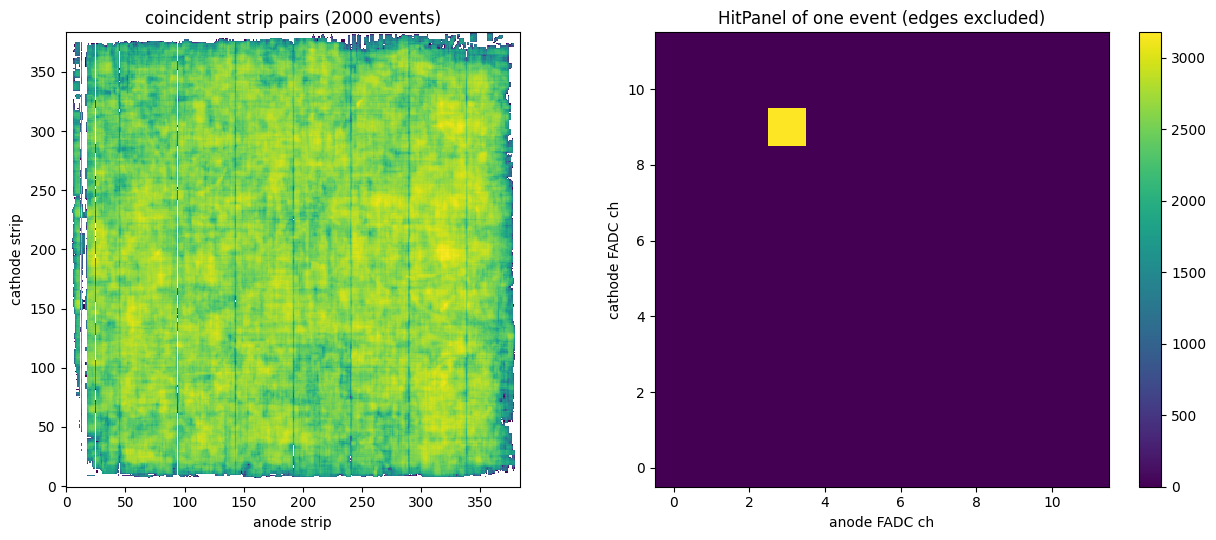

In [4]:
img = np.zeros((384, 384))
panel_last = None
for k, e in enumerate(tu.iter_raw(RAW, ["hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock"], n=2000)):
    sa, ca, sc, cc = e["hit_a_strip"], e["hit_a_clock"], e["hit_c_strip"], e["hit_c_clock"]
    pairs_a, pairs_c = [], []
    for clk in np.intersect1d(ca, cc):
        a, c = sa[ca == clk], sc[cc == clk]
        pairs_a.append(np.repeat(a, len(c))); pairs_c.append(np.tile(c, len(a)))
    if pairs_a:
        pa, pc = np.concatenate(pairs_a), np.concatenate(pairs_c)
        np.add.at(img, (pa, pc), 1)
        edge = (pa % 32 >= 4) & (pa % 32 < 28) & (pc % 32 >= 4) & (pc % 32 < 28)
        if edge.sum() > 100:
            panel_last = np.zeros((12, 12)); np.add.at(panel_last, (pa[edge] // 32, pc[edge] // 32), 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ax[0].pcolormesh(np.arange(385) - 0.5, np.arange(385) - 0.5, img.T, norm="log"); ax[0].set_aspect("equal")
ax[0].set_xlabel("anode strip"); ax[0].set_ylabel("cathode strip"); ax[0].set_title("coincident strip pairs (2000 events)")
m = ax[1].pcolormesh(np.arange(13) - 0.5, np.arange(13) - 0.5, panel_last.T); ax[1].set_aspect("equal")
ax[1].set_xlabel("anode FADC ch"); ax[1].set_ylabel("cathode FADC ch"); ax[1].set_title("HitPanel of one event (edges excluded)")
fig.colorbar(m, ax=ax[1]); fig.tight_layout(); plt.show()

## 4. TPC のエネルギースペクトル

TPC_Calibration が求めた `Ke` は再構成ツリー `single_hit` に入っています(シングルヒットとして再構成できた `err_flag == 0` の行)。

In [5]:
# 全チェーンの出力(DataIO と共有、Per02 の先頭 50000 イベント)
OUT = tu.get_reconstructed("Per02", 50000)
ev = tu.load_single_hit(OUT, branches=['err_flag', 'Ke'])
print("err_flag == 0:", len(ev["err_flag"]))

Per02_50000.root は既にあるので再実行しません(overwrite=True で作り直し)


err_flag == 0: 26697


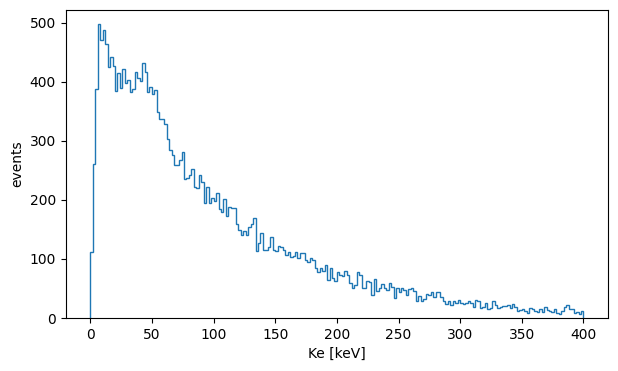

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ev["Ke"], bins=200, range=(0, 400), histtype="step")
ax.set_xlabel("Ke [keV]"); ax.set_ylabel("events")
plt.show()